# 06 - Decision Tree

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and test Decision Tree on the processed PhiUSIIL data (Experiment 1), compare different feature sets, and test the URL-only version on the external dataset (Experiment 2).

**About the model:** A Decision Tree asks a series of yes/no questions about the features, like "Is URLSimilarityIndex below 80?". Each answer leads to the next question until it reaches a final answer: phishing or legitimate. It is easy to understand and it does not need scaling.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, load_url_experiment, sample_rows
from src.features import extract_url_features
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_by_source,
    cross_validate_model,
    evaluate_model,
    fit_with_weights,
    make_cv,
    make_sample_weights,
    plot_confusion_matrix,
    save_results,
    tune_by_source,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

We try different tree depths (how many questions the tree can ask) and the smallest number of URLs allowed in a leaf. A very deep tree can memorise the training data, so these settings help us control overfitting. That gives 12 combinations. A single tree is fast, so we tune on the full training set.

In [3]:
MODEL_NAME = "Decision Tree"
model = DecisionTreeClassifier(random_state=RANDOM_STATE)

param_grid = {
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [1, 5, 10],
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'max_depth': 5, 'min_samples_leaf': 1}
Best cross-validation F1: 1.0000


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,1.0,0.0
Precision,1.0,0.0
Recall,1.0,0.0
F1,1.0,0.0
ROC-AUC,1.0,0.0


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.6 seconds


,Test Score
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
ROC-AUC,1.0


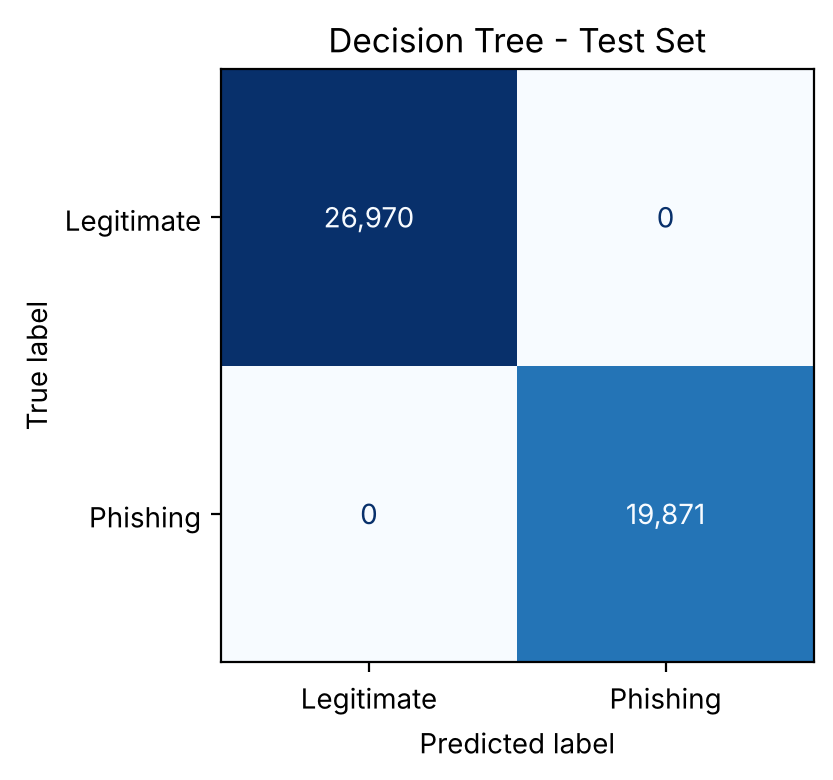

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

### Feature Importance

Tree models can tell us which features they used most to make decisions. We show the 15 most important features.

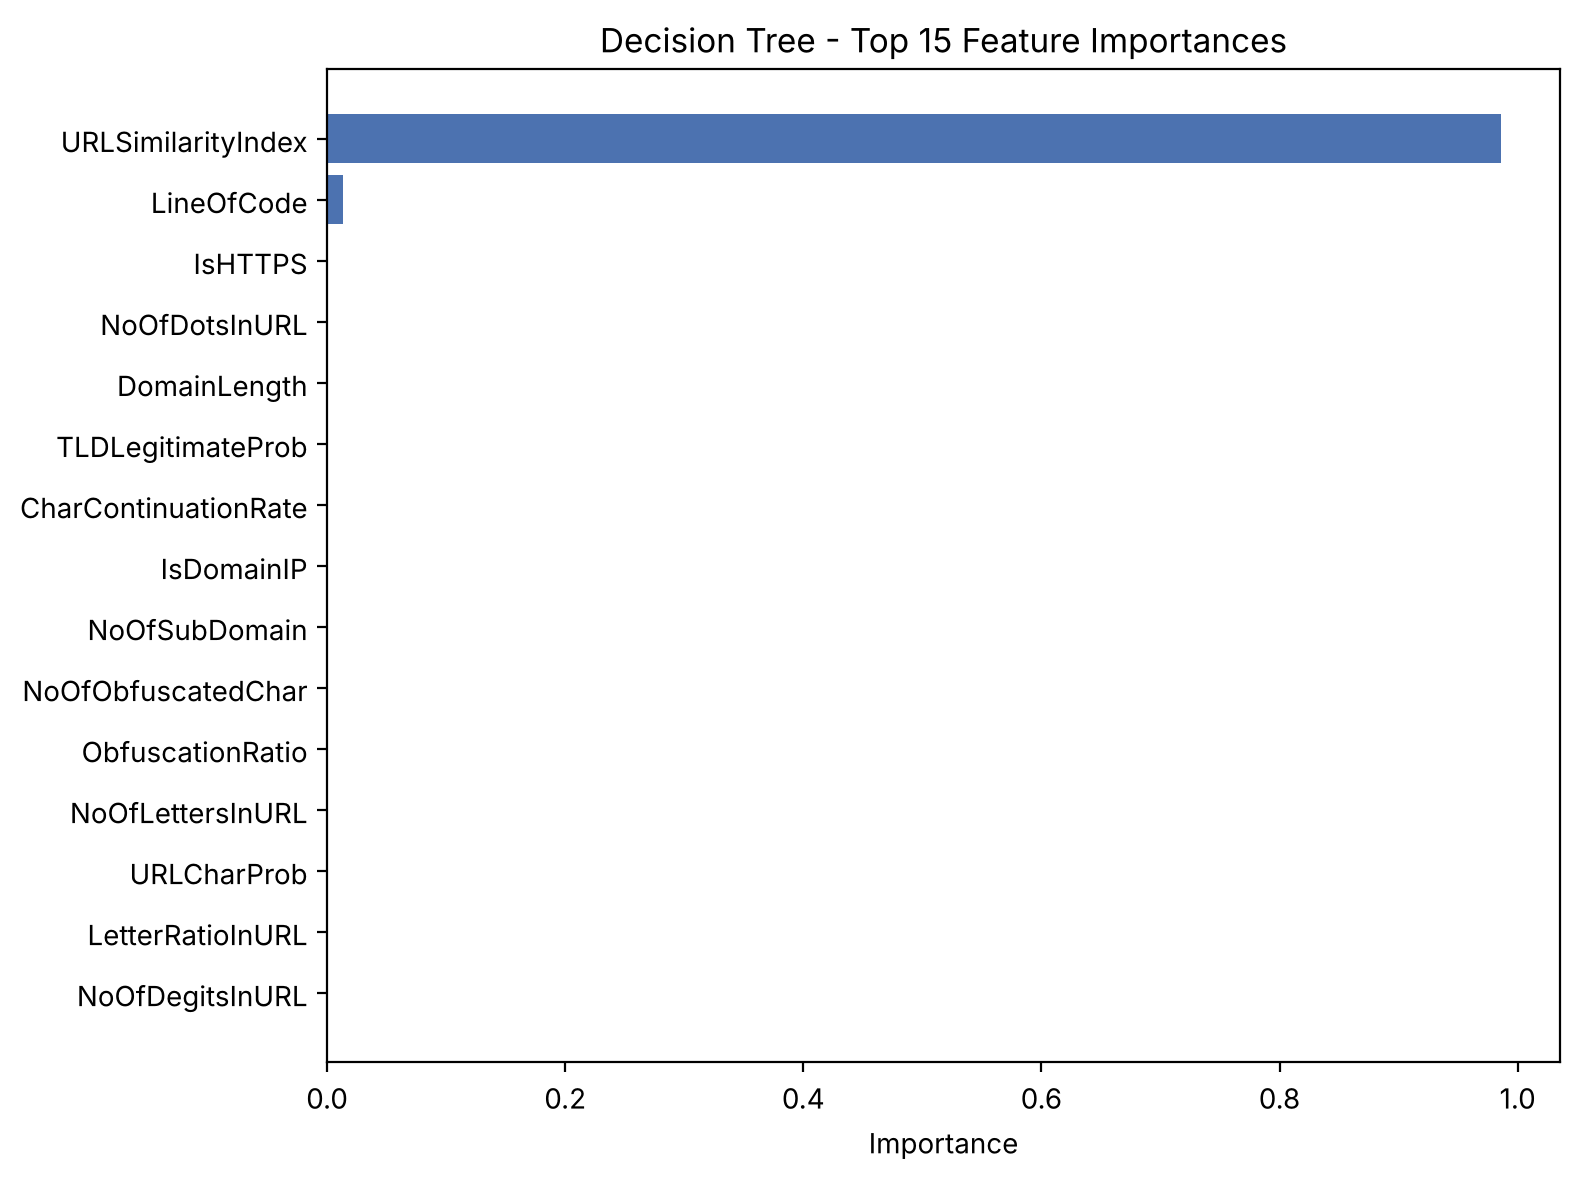

,Importance
URLSimilarityIndex,0.9863
LineOfCode,0.0133
IsHTTPS,0.0004
NoOfDotsInURL,0.0000
DomainLength,0.0000
TLDLegitimateProb,0.0000
CharContinuationRate,0.0000
IsDomainIP,0.0000
NoOfSubDomain,0.0000
NoOfObfuscatedChar,0.0000


In [8]:
importance = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_features = importance.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features.index[::-1], top_features.values[::-1], color="#4C72B0")
ax.set_title(f"{MODEL_NAME} - Top 15 Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "decision_tree_feature_importance.png", dpi=300)
plt.show()

top_features.round(4).to_frame("Importance")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,1.0000,1.0000,1.0000,1.0000,1.0000
Original features only,1.0000,1.0000,1.0000,1.0000,1.0000
Without URLSimilarityIndex,0.9945,0.9875,0.9997,0.9935,0.9984


## 5. Experiment 2: URL Features Only

In real use, DetectIt only gets a URL, not the HTML of the page. So here the model only uses the **40 URL features** that we can create from any URL (18 from `02_preprocessing.ipynb` and 22 new ones from `03_external_dataset.ipynb`).

In the first version of this experiment, we trained only on PhiUSIIL, and every model scored about 50% on the Kaggle dataset, because the legitimate URLs in the two datasets look very different. Now we train on **both datasets**:

- **Training set:** PhiUSIIL training set (80%) + Kaggle training part (80%)
- **Test sets:** PhiUSIIL test set (20%) and Kaggle test part (20%). We test on them **separately**. The PhiUSIIL test set is about 21 times bigger, so one combined score would mostly show the PhiUSIIL score and hide how the model does on Kaggle URLs.

No URL is in both a training set and a test set (checked in `02_preprocessing.ipynb` and `03_external_dataset.ipynb`).

In [10]:
X_url_train, y_url_train, url_source, url_test_sets = load_url_experiment()

print(f"Training set: {X_url_train.shape[0]:,} rows | {X_url_train.shape[1]} features")
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    print(f"{test_name}: {X_url_test.shape[0]:,} rows")

Training set: 196,230 rows | 40 features
PhiUSIIL test set: 46,841 rows
Kaggle test set: 2,217 rows


### Sample Weights

The training set has about 21 times more PhiUSIIL URLs than Kaggle URLs. Without help, the model would mostly learn PhiUSIIL patterns and almost ignore the Kaggle URLs. So we give each Kaggle URL a bigger **sample weight**. A weight of 21 means the model treats one mistake on that URL like 21 mistakes, so both datasets matter equally during training.

In [11]:
url_weights = make_sample_weights(url_source)

pd.DataFrame({
    "Training URLs": url_source.value_counts(),
    "Weight per URL": pd.Series(url_weights, index=url_source).groupby(level=0).first(),
}).round(2)

,Training URLs,Weight per URL
Source,,
Kaggle,8867,21.13
PhiUSIIL,187363,1.00


### Hyperparameter Tuning

The best settings from Section 1 were chosen for 69 features on PhiUSIIL only. There, a small tree with 5 levels was enough, because `URLSimilarityIndex` almost separates the classes by itself. URL features are much weaker, so the tree needs more questions to separate the classes, and we tune again. For every combination below, we run 3-fold cross-validation on the training set (with sample weights) and calculate the F1-score separately for PhiUSIIL URLs and Kaggle URLs. We keep the combination with the highest **average of the two F1-scores**, so the model works well on both datasets, not just on the bigger one. The test sets are not used here.

We try deeper trees, two leaf sizes, and two ways of measuring how good a split is (`gini` and `entropy`). That gives 16 combinations. A single tree is fast, so we tune on the full training set.

In [12]:
url_param_grid = {
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 3],
    "criterion": ["gini", "entropy"],
}

X_url_tune, y_url_tune, url_source_tune = X_url_train, y_url_train, url_source

url_tuning, url_best_params = tune_by_source(model, url_param_grid, X_url_tune, y_url_tune, url_source_tune)
url_best_model = clone(model).set_params(**url_best_params)

print(f"Best settings: {url_best_params}")
url_tuning.round(4)

Best settings: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 3}


,criterion,max_depth,min_samples_leaf,PhiUSIIL F1,Kaggle F1,Mean F1
0,entropy,15.0,3,0.9827,0.8454,0.9140
1,entropy,15.0,1,0.9839,0.8427,0.9133
2,gini,15.0,1,0.9824,0.8424,0.9124
3,gini,20.0,1,0.9860,0.8380,0.9120
4,entropy,None,3,0.9854,0.8373,0.9114
5,entropy,10.0,1,0.9842,0.8371,0.9106
6,entropy,20.0,3,0.9823,0.8385,0.9104
7,gini,15.0,3,0.9808,0.8400,0.9104
8,entropy,20.0,1,0.9845,0.8353,0.9099
9,entropy,10.0,3,0.9839,0.8356,0.9098


### Cross-Validation

We check the best settings with 5-fold cross-validation and calculate the scores for PhiUSIIL URLs and Kaggle URLs separately. The Kaggle scores here are used to choose the best model for Experiment 2. The test sets are only used to report the final scores.

In [13]:
url_cv_results = cross_validate_by_source(url_best_model, X_url_tune, y_url_tune, url_source_tune)
url_cv_results.round(4)

,PhiUSIIL Mean,PhiUSIIL Std,Kaggle Mean,Kaggle Std
Accuracy,0.9875,0.0020,0.8306,0.0046
Precision,0.9991,0.0004,0.7826,0.0155
Recall,0.9713,0.0046,0.9124,0.0217
F1,0.9850,0.0024,0.8422,0.0029
ROC-AUC,0.9957,0.0010,0.8879,0.0041


### Final Test

We train two models with the best settings and test both of them on both test sets:

- **Trained on PhiUSIIL only:** the first version of this experiment, with the 40 URL features.
- **Trained on both datasets:** the new version, with sample weights.

Comparing the two shows how much adding Kaggle URLs to the training set helps.

In [14]:
phiusiil_only = (url_source == "PhiUSIIL").to_numpy()

start = time.perf_counter()
url_model = fit_with_weights(clone(url_best_model), X_url_train, y_url_train, url_weights)
url_train_time = time.perf_counter() - start

url_models = {
    "Trained on PhiUSIIL only": clone(url_best_model).fit(X_url_train[phiusiil_only], y_url_train[phiusiil_only]),
    "Trained on both datasets": url_model,
}

url_results = {}
for train_name, model_version in url_models.items():
    for test_name, (X_url_test, y_url_test) in url_test_sets.items():
        url_results[(train_name, test_name)] = evaluate_model(model_version, X_url_test, y_url_test)

print(f"Training time (both datasets): {url_train_time:.1f} seconds")
pd.DataFrame(url_results).T.round(4)

Training time (both datasets): 0.9 seconds


Accuracy  Precision  Recall  \
Trained on PhiUSIIL only PhiUSIIL test set    0.9982     0.9995  0.9962   
                         Kaggle test set      0.4957     0.4957  0.9991   
Trained on both datasets PhiUSIIL test set    0.9844     0.9986  0.9646   
                         Kaggle test set      0.8349     0.8072  0.8763   

                                                F1  ROC-AUC  
Trained on PhiUSIIL only PhiUSIIL test set  0.9978   0.9982  
                         Kaggle test set    0.6626   0.5000  
Trained on both datasets PhiUSIIL test set  0.9813   0.9960  
                         Kaggle test set    0.8403   0.8940

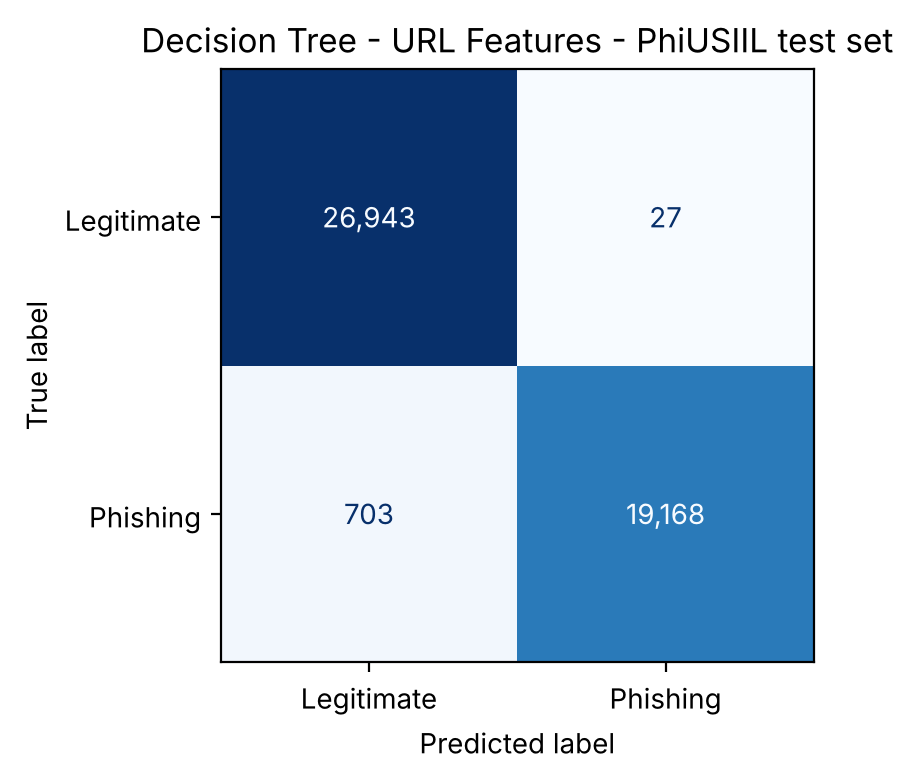

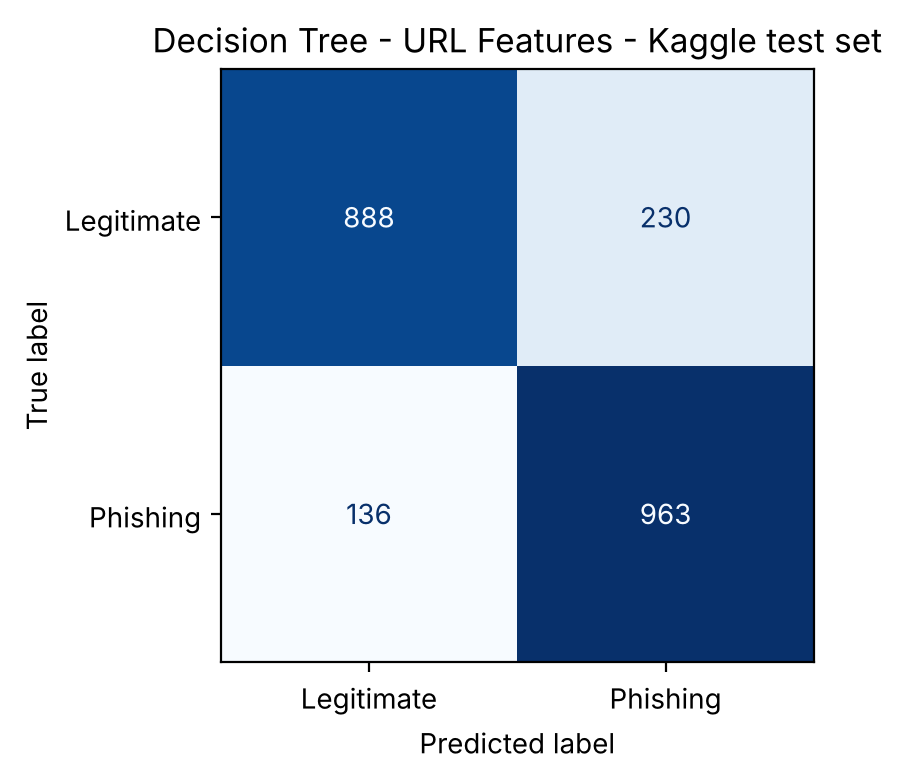

In [15]:
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    plot_confusion_matrix(y_url_test, url_model.predict(X_url_test), f"{MODEL_NAME} - URL Features - {test_name}")

### Did the 22 New URL Features Help?

We train the same model on both datasets again, but only with the 18 URL features from `02_preprocessing.ipynb`, and compare it with the model that uses all 40 URL features.

In [16]:
base_url_features = list(extract_url_features("example.com"))
base_url_model = fit_with_weights(clone(url_best_model), X_url_train[base_url_features], y_url_train, url_weights)

url_feature_results = {}
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    url_feature_results[("18 URL features", test_name)] = evaluate_model(base_url_model, X_url_test[base_url_features], y_url_test)
    url_feature_results[("40 URL features", test_name)] = url_results[("Trained on both datasets", test_name)]

pd.DataFrame(url_feature_results).T.round(4)

,,Accuracy,Precision,Recall,F1,ROC-AUC
18 URL features,PhiUSIIL test set,0.9617,0.9963,0.9130,0.9528,0.9938
40 URL features,PhiUSIIL test set,0.9844,0.9986,0.9646,0.9813,0.9960
18 URL features,Kaggle test set,0.8047,0.7808,0.8426,0.8105,0.8536
40 URL features,Kaggle test set,0.8349,0.8072,0.8763,0.8403,0.8940


### Feature Importance

We show the 15 URL features the final Experiment 2 model used most.

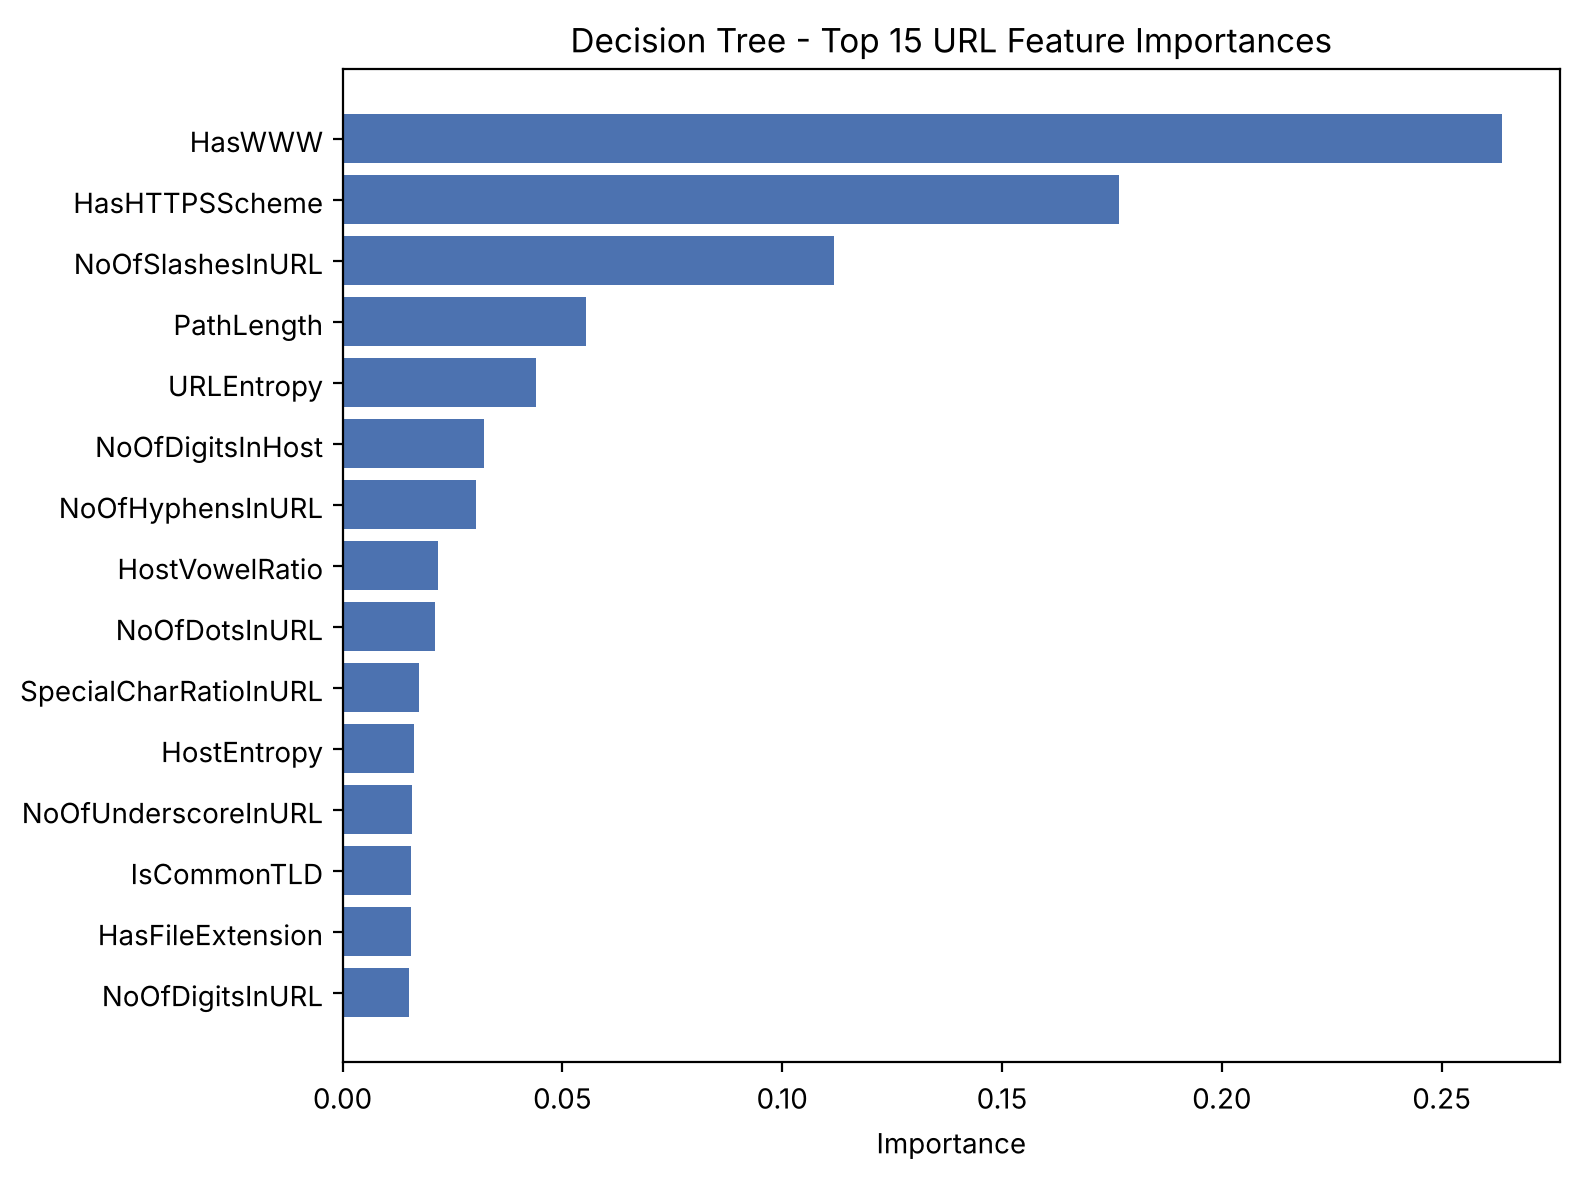

,Importance
HasWWW,0.2637
HasHTTPSScheme,0.1765
NoOfSlashesInURL,0.1119
PathLength,0.0554
URLEntropy,0.0440
NoOfDigitsInHost,0.0322
NoOfHyphensInURL,0.0305
HostVowelRatio,0.0218
NoOfDotsInURL,0.0210
SpecialCharRatioInURL,0.0173


In [17]:
url_importance = pd.Series(url_model.feature_importances_, index=X_url_train.columns).sort_values(ascending=False)
top_url_features = url_importance.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_url_features.index[::-1], top_url_features.values[::-1], color="#4C72B0")
ax.set_title(f"{MODEL_NAME} - Top 15 URL Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "decision_tree_url_feature_importance.png", dpi=300)
plt.show()

top_url_features.round(4).to_frame("Importance")

### Does the Model Depend on `www` and HTTPS?

In PhiUSIIL, every legitimate URL starts with `www` and uses HTTPS. So a model may learn that a URL without `www` or HTTPS is suspicious, and a legitimate website without them might get a false alarm.

To check how much the model depends on this, we remove `http://`, `https://` and `www.` from every URL before creating the features. This removes `HasWWW` and `HasHTTPSScheme`, and also removes this information from the other features (for example, `FullURLLength` no longer counts `https://www.`). We then train the same model with the same settings on both datasets and compare the scores.

In [18]:
X_clean_train, _, _, clean_test_sets = load_url_experiment(clean_urls=True)
clean_model = fit_with_weights(clone(url_best_model), X_clean_train, y_url_train, url_weights)

clean_results = {}
for test_name, (X_clean_test, y_clean_test) in clean_test_sets.items():
    clean_results[("With www and HTTPS", test_name)] = url_results[("Trained on both datasets", test_name)]
    clean_results[("Without www and HTTPS", test_name)] = evaluate_model(clean_model, X_clean_test, y_clean_test)

print(f"Features without www and HTTPS: {X_clean_train.shape[1]}")
pd.DataFrame(clean_results).T.round(4)

Features without www and HTTPS: 38


,,Accuracy,Precision,Recall,F1,ROC-AUC
With www and HTTPS,PhiUSIIL test set,0.9844,0.9986,0.9646,0.9813,0.9960
Without www and HTTPS,PhiUSIIL test set,0.8699,0.9479,0.7336,0.8271,0.8928
With www and HTTPS,Kaggle test set,0.8349,0.8072,0.8763,0.8403,0.8940
Without www and HTTPS,Kaggle test set,0.8164,0.7808,0.8753,0.8254,0.8729


## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [19]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - Cross-validation - PhiUSIIL", **url_cv_results["PhiUSIIL Mean"].to_dict()},
    {"Experiment": "URL features - Cross-validation - Kaggle", **url_cv_results["Kaggle Mean"].to_dict()},
]

for (train_name, test_name), scores in url_results.items():
    row = {"Experiment": f"URL features - {train_name} - {test_name}", **scores}
    if train_name == "Trained on both datasets" and test_name == "PhiUSIIL test set":
        row["Train Time (s)"] = url_train_time
    results.append(row)

for (feature_name, test_name), scores in url_feature_results.items():
    if feature_name == "18 URL features":
        results.append({"Experiment": f"URL features - Trained on both datasets (18 URL features) - {test_name}", **scores})

for (version, test_name), scores in clean_results.items():
    if version == "Without www and HTTPS":
        results.append({"Experiment": f"URL features - Trained on both datasets (without www and HTTPS) - {test_name}", **scores})

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,Decision Tree,Cross-validation,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
1,Decision Tree,Test set - All features,1.0000,1.0000,1.0000,1.0000,1.0000,0.6073
2,Decision Tree,Test set - Original features only,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
3,Decision Tree,Test set - Without URLSimilarityIndex,0.9945,0.9875,0.9997,0.9935,0.9984,NaN
4,Decision Tree,URL features - Cross-validation - PhiUSIIL,0.9875,0.9991,0.9713,0.9850,0.9957,NaN
5,Decision Tree,URL features - Cross-validation - Kaggle,0.8306,0.7826,0.9124,0.8422,0.8879,NaN
6,Decision Tree,URL features - Trained on PhiUSIIL only - PhiU...,0.9982,0.9995,0.9962,0.9978,0.9982,NaN
7,Decision Tree,URL features - Trained on PhiUSIIL only - Kagg...,0.4957,0.4957,0.9991,0.6626,0.5000,NaN
8,Decision Tree,URL features - Trained on both datasets - PhiU...,0.9844,0.9986,0.9646,0.9813,0.9960,0.9359
9,Decision Tree,URL features - Trained on both datasets - Kagg...,0.8349,0.8072,0.8763,0.8403,0.8940,NaN


## 7. Findings

- **Test score:** The Decision Tree made **no mistakes on the 46,841 test URLs** (accuracy 100%). Every phishing URL and every legitimate URL was classified correctly.
- **Stability:** The 5-fold cross-validation scores were the same in every fold (standard deviation 0), so the result is stable and not a lucky split.
- **Best settings:** `max_depth = 5` and `min_samples_leaf = 1`. A small tree with only 5 levels of questions was enough. A small tree is easier to understand and less likely to overfit.
- **Feature importance:** The tree depends almost completely on `URLSimilarityIndex` (about 99% of the importance). `LineOfCode` and `IsHTTPS` are used a little, and the other features are almost not used.
- **New features:** Using only the original features gave the same score, so our new features did not change the result for the Decision Tree.
- **Without `URLSimilarityIndex`:** Accuracy dropped to 99.45% (258 mistakes). The tree now called 252 legitimate URLs phishing and missed 6 phishing URLs. A single tree depends on its strongest feature much more than Random Forest does, which made only 3 mistakes without it.

### Experiment 2: URL Features Only

- **Training on both datasets fixed the main problem.** When trained on PhiUSIIL only, the tree scored 99.8% on the PhiUSIIL test set but only **49.6% on the Kaggle test set** (ROC-AUC 0.50, no better than guessing), because it called almost every Kaggle URL phishing. After adding the Kaggle training part with sample weights, it scored **83.5% on the Kaggle test set** (F1 0.840) and **98.4% on the PhiUSIIL test set** (F1 0.981).
- **Kaggle test set:** out of 1,118 legitimate URLs, 230 were called phishing (false alarms), and out of 1,099 phishing URLs, 136 were missed (recall 87.6%).
- **PhiUSIIL test set:** only 27 false alarms, but 703 of 19,871 phishing URLs were missed (recall 96.5%).
- **Hyperparameter tuning:** in Experiment 1 a tree with 5 levels was enough, because `URLSimilarityIndex` almost separates the classes by itself. URL features are weaker, so the tree needs more questions. The best settings were `max_depth = 15`, `min_samples_leaf = 3` and `criterion = "entropy"`. Trees with no depth limit were better on PhiUSIIL but worse on Kaggle, which shows they memorise PhiUSIIL-only patterns.
- **Stability:** the cross-validation F1 was 0.985 ± 0.002 for PhiUSIIL URLs and 0.842 ± 0.003 for Kaggle URLs, close to the test scores, so the test result is reliable.
- **The 22 new URL features helped.** With only the 18 URL features from `02_preprocessing.ipynb`, the tree scored 80.5% on Kaggle and 96.2% on PhiUSIIL. With all 40 features, it scored 83.5% and 98.4%.
- **Feature importance:** `HasWWW` (26%, a new feature), `HasHTTPSScheme` (18%) and `NoOfSlashesInURL` (11%) are the most important.
- **Without `www` and HTTPS:** the Kaggle score dropped only a little (83.5% → 81.6%), but the PhiUSIIL score dropped a lot (98.4% → 87.0%). So these two signals are useful in both datasets, but a legitimate website without `www` or HTTPS is more likely to get a false alarm.
- **Compared with the other models:** a single tree is weaker than Random Forest (88.1%) and XGBoost (89.0%) on Kaggle URLs. Many trees voting together make fewer mistakes than one tree on new data.